In [44]:


# load the datasets

import pandas as pd
import requests
import zipfile
import io

# GitHub repository
zip_url = (
    "https://raw.githubusercontent.com/"
    "devadharshinimurugan06-commits/"
    "Movie_recommendation_syntecxhub/"
    "main/ml-latest-small.zip"
)

# Download the ZIP file
response = requests.get(zip_url, timeout=60)
response.raise_for_status()

# Extract and load CSV files directly from the ZIP
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    movies = pd.read_csv(z.open("ml-latest-small/movies.csv"))
    ratings = pd.read_csv(z.open("ml-latest-small/ratings.csv"))
    tags = pd.read_csv(z.open("ml-latest-small/tags.csv"))
    links = pd.read_csv(z.open("ml-latest-small/links.csv"))

print("Dataset loaded successfully!")
print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)
print("Tags shape:", tags.shape)
print("Links shape:", links.shape)

Dataset loaded successfully!
Movies shape: (9742, 3)
Ratings shape: (100836, 4)
Tags shape: (3683, 4)
Links shape: (9742, 3)


In [45]:

# STEP 2: View the first five rows of each dataset

print("MOVIES")
display(movies.head())

print("RATINGS")
display(ratings.head())

print("TAGS")
display(tags.head())

print("LINKS")
display(links.head())

MOVIES


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


RATINGS


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


TAGS


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


LINKS


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


In [46]:

# STEP 3: Dataset information

print("MOVIES INFO")
movies.info()

print("\nRATINGS INFO")
ratings.info()

print("\nTAGS INFO")
tags.info()

print("\nLINKS INFO")
links.info()

MOVIES INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB

RATINGS INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB

TAGS INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3683 entries, 0 to 3682
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   userId     3683 non-null 

In [47]:

# STEP 4: Statistical summary

print("MOVIES DESCRIPTION")
display(movies.describe(include="all"))

print("RATINGS DESCRIPTION")
display(ratings.describe())

print("TAGS DESCRIPTION")
display(tags.describe(include="all"))

print("LINKS DESCRIPTION")
display(links.describe())

MOVIES DESCRIPTION


,movieId,title,genres
count,9742.000000,9742,9742
unique,NaN,9737,951
top,NaN,Emma (1996),Drama
freq,NaN,2,1053
mean,42200.353623,NaN,NaN
std,52160.494854,NaN,NaN
min,1.000000,NaN,NaN
25%,3248.250000,NaN,NaN
50%,7300.000000,NaN,NaN
75%,76232.000000,NaN,NaN


RATINGS DESCRIPTION


,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09


TAGS DESCRIPTION


,userId,movieId,tag,timestamp
count,3683.000000,3683.000000,3683,3.683000e+03
unique,NaN,NaN,1589,NaN
top,NaN,NaN,In Netflix queue,NaN
freq,NaN,NaN,131,NaN
mean,431.149335,27252.013576,NaN,1.320032e+09
std,158.472553,43490.558803,NaN,1.721025e+08
min,2.000000,1.000000,NaN,1.137179e+09
25%,424.000000,1262.500000,NaN,1.137521e+09
50%,474.000000,4454.000000,NaN,1.269833e+09
75%,477.000000,39263.000000,NaN,1.498457e+09


LINKS DESCRIPTION


,movieId,imdbId,tmdbId
count,9742.000000,9.742000e+03,9734.000000
mean,42200.353623,6.771839e+05,55162.123793
std,52160.494854,1.107228e+06,93653.481487
min,1.000000,4.170000e+02,2.000000
25%,3248.250000,9.518075e+04,9665.500000
50%,7300.000000,1.672605e+05,16529.000000
75%,76232.000000,8.055685e+05,44205.750000
max,193609.000000,8.391976e+06,525662.000000


In [48]:

# Missing values and duplicate rows

datasets = {
    "Movies": movies,
    "Ratings": ratings,
    "Tags": tags,
    "Links": links
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print("Duplicate rows:", df.duplicated().sum())
    print("\nMissing values per column:")
    print(df.isnull().sum())


--- Movies ---
Rows: 9742
Columns: 3
Duplicate rows: 0

Missing values per column:
movieId    0
title      0
genres     0
dtype: int64

--- Ratings ---
Rows: 100836
Columns: 4
Duplicate rows: 0

Missing values per column:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

--- Tags ---
Rows: 3683
Columns: 4
Duplicate rows: 0

Missing values per column:
userId       0
movieId      0
tag          0
timestamp    0
dtype: int64

--- Links ---
Rows: 9742
Columns: 3
Duplicate rows: 0

Missing values per column:
movieId    0
imdbId     0
tmdbId     8
dtype: int64


In [49]:

#  Basic dataset analysis

print("Unique movies:", movies["movieId"].nunique())
print("Unique users:", ratings["userId"].nunique())
print("Unique rated movies:", ratings["movieId"].nunique())
print("Unique tags:", tags["tag"].nunique())

print("\nRating distribution:")
print(ratings["rating"].value_counts().sort_index())

print("\nAverage rating:", round(ratings["rating"].mean(), 2))
print("Minimum rating:", ratings["rating"].min())
print("Maximum rating:", ratings["rating"].max())

print("\nMost frequent genres:")
genre_counts = (
    movies["genres"]
    .str.split("|")
    .explode()
    .value_counts()
)
print(genre_counts.head(15))

print("\nMost frequent tags:")
print(tags["tag"].value_counts().head(15))

Unique movies: 9742
Unique users: 610
Unique rated movies: 9724
Unique tags: 1589

Rating distribution:
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64

Average rating: 3.5
Minimum rating: 0.5
Maximum rating: 5.0

Most frequent genres:
genres
Drama          4361
Comedy         3756
Thriller       1894
Action         1828
Romance        1596
Adventure      1263
Crime          1199
Sci-Fi          980
Horror          978
Fantasy         779
Children        664
Animation       611
Mystery         573
Documentary     440
War             382
Name: count, dtype: int64

Most frequent tags:
tag
In Netflix queue      131
atmospheric            36
thought-provoking      24
superhero              24
surreal                23
funny                  23
Disney                 23
religion               22
quirky                 21
sci-fi                 21
dark comedy            21
psych

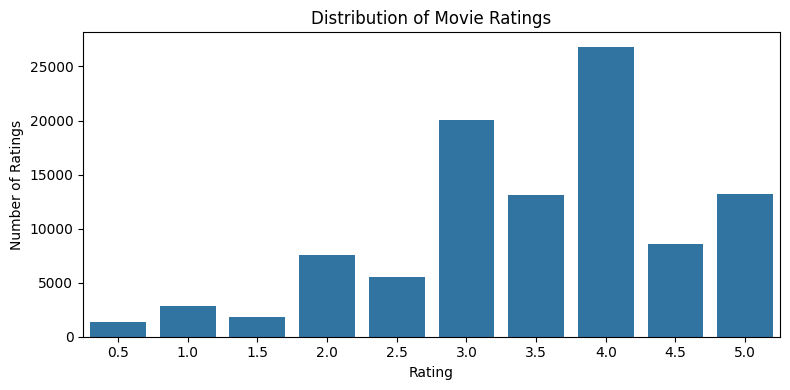

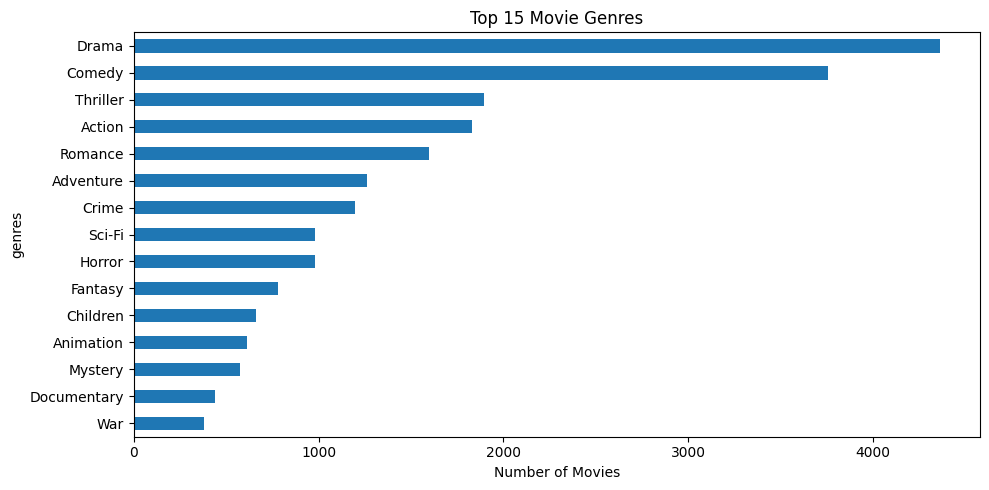

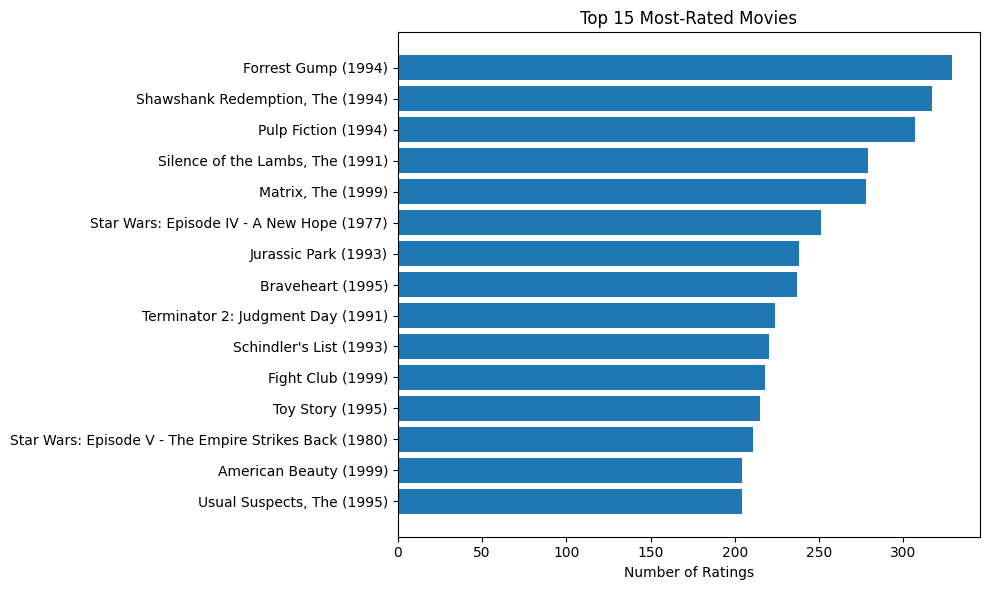

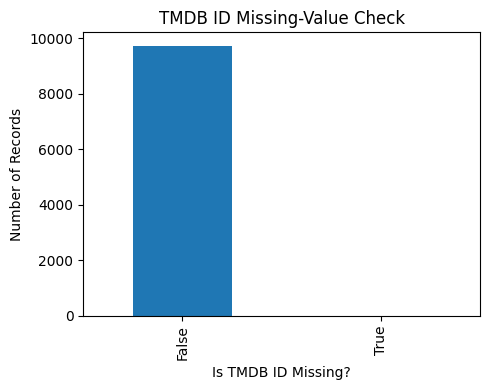

In [50]:

#  EDA visualizations

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Rating distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=ratings, x="rating")
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()

# 2. Top 15 genres
plt.figure(figsize=(10, 5))
genre_counts.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Movie Genres")
plt.xlabel("Number of Movies")
plt.tight_layout()
plt.show()

# 3. Top 15 most-rated movies
rating_counts = ratings["movieId"].value_counts().head(15)
top_movies = movies[movies["movieId"].isin(rating_counts.index)].copy()
top_movies["rating_count"] = top_movies["movieId"].map(rating_counts)
top_movies = top_movies.sort_values("rating_count")

plt.figure(figsize=(10, 6))
plt.barh(top_movies["title"], top_movies["rating_count"])
plt.title("Top 15 Most-Rated Movies")
plt.xlabel("Number of Ratings")
plt.tight_layout()
plt.show()

# 4. Missing TMDB identifiers
plt.figure(figsize=(5, 4))
links["tmdbId"].isnull().value_counts().plot(kind="bar")
plt.title("TMDB ID Missing-Value Check")
plt.xlabel("Is TMDB ID Missing?")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


In [51]:

#  Clean movie metadata

import numpy as np

movies_clean = movies.copy()
tags_clean = tags.copy()
links_clean = links.copy()

# Clean movie titles
movies_clean["title"] = (
    movies_clean["title"]
    .astype("string")
    .str.strip()
)

# Clean genres
movies_clean["genres"] = (
    movies_clean["genres"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# The "(no genres listed)" value means genre information is unavailable.
movies_clean["genres"] = movies_clean["genres"].replace(
    "(no genres listed)", ""
)

# Clean tags
tags_clean["tag"] = (
    tags_clean["tag"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Remove empty tags
tags_clean = tags_clean[tags_clean["tag"] != ""].copy()

# Handle missing TMDB IDs without deleting movie rows
links_clean["tmdbId"] = pd.to_numeric(
    links_clean["tmdbId"], errors="coerce"
)

print("Movies after cleaning:", movies_clean.shape)
print("Tags after cleaning:", tags_clean.shape)
print("Missing TMDB IDs retained:", links_clean["tmdbId"].isna().sum())
print("Duplicate movie IDs:", movies_clean["movieId"].duplicated().sum())


Movies after cleaning: (9742, 3)
Tags after cleaning: (3683, 4)
Missing TMDB IDs retained: 8
Duplicate movie IDs: 0


In [52]:

#  Create combined text features

# Combine tags associated with each movie
movie_tags = (
    tags_clean.groupby("movieId")["tag"]
    .apply(lambda values: " ".join(values))
    .reset_index(name="tags_text")
)

# Merge tags into movie metadata
movies_features = movies_clean.merge(
    movie_tags,
    on="movieId",
    how="left",
    validate="one_to_one"
)

movies_features["tags_text"] = movies_features["tags_text"].fillna("")

# Combine genres and tags into the content feature
movies_features["content"] = (
    movies_features["genres"].fillna("").str.replace("|", " ", regex=False)
    + " "
    + movies_features["tags_text"]
)

movies_features["content"] = (
    movies_features["content"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print(movies_features[
    ["movieId", "title", "genres", "tags_text", "content"]
].head(10))

print("\nMovies with empty content:",
      (movies_features["content"] == "").sum())


   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   
5        6                         Heat (1995)   
6        7                      Sabrina (1995)   
7        8                 Tom and Huck (1995)   
8        9                 Sudden Death (1995)   
9       10                    GoldenEye (1995)   

                                        genres  \
0  Adventure|Animation|Children|Comedy|Fantasy   
1                   Adventure|Children|Fantasy   
2                               Comedy|Romance   
3                         Comedy|Drama|Romance   
4                                       Comedy   
5                        Action|Crime|Thriller   
6                               Comedy|Romance   
7                           Adventure|Children   

In [53]:

# Check and handle empty content

empty_mask = movies_features["content"].str.strip().eq("")

print("Movies with empty content:", empty_mask.sum())

# Use the movie title as a fallback feature for these rows
movies_features.loc[empty_mask, "content"] = (
    movies_features.loc[empty_mask, "title"]
    .str.replace(r"\(\d{4}\)", "", regex=True)
    .str.strip()
    .str.lower()
)

print(
    "Empty content after handling:",
    movies_features["content"].str.strip().eq("").sum()
)


Movies with empty content: 33
Empty content after handling: 0


In [54]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

# Create TF-IDF features
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True
)

tfidf_matrix = tfidf.fit_transform(
    movies_features["content"].fillna("")
)

print("Movies:", tfidf_matrix.shape[0])
print("TF-IDF features:", tfidf_matrix.shape[1])
print("Empty content rows:", (movies_features["content"].fillna("").str.strip() == "").sum())

# Build nearest-neighbor model
knn_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=11
)

knn_model.fit(tfidf_matrix)

print("TF-IDF model created successfully!")


Movies: 9742
TF-IDF features: 5640
Empty content rows: 0
TF-IDF model created successfully!


In [55]:
# train test split

import pandas as pd
import numpy as np

# Keep users who have rated at least 5 movies
user_counts = ratings.groupby("userId").size()
eligible_users = user_counts[user_counts >= 5].index

eval_ratings = ratings[
    ratings["userId"].isin(eligible_users)
].copy()

# Reproducible 80/20 split for each user
train_ratings = (
    eval_ratings.groupby("userId", group_keys=False)
    .sample(frac=0.8, random_state=42)
)

test_ratings = eval_ratings.drop(train_ratings.index).copy()

# Movies already rated by each user in training data
train_seen = (
    train_ratings.groupby("userId")["movieId"]
    .apply(set)
    .to_dict()
)

# Relevant test movies: ratings of 4 stars or higher
test_relevant = (
    test_ratings[test_ratings["rating"] >= 4.0]
    .groupby("userId")["movieId"]
    .apply(set)
    .to_dict()
)

# Create movieId-to-row-index mapping for TF-IDF matrix
movie_to_index = {
    movie_id: idx
    for idx, movie_id in enumerate(movies_features["movieId"])
}

print("Eligible users:", len(eligible_users))
print("Training ratings:", len(train_ratings))
print("Testing ratings:", len(test_ratings))
print("Users with relevant test movies:", len(test_relevant))
print("Train/test split completed successfully!")


Eligible users: 610
Training ratings: 80672
Testing ratings: 20164
Users with relevant test movies: 601
Train/test split completed successfully!


In [56]:

from sklearn.preprocessing import normalize

# Build a profile from each user's high-rated training movies
user_profiles = {}

for user_id, group in train_ratings.groupby("userId"):
    liked_movies = group[group["rating"] >= 4.0]["movieId"]

    indices = [
        movie_to_index[mid]
        for mid in liked_movies
        if mid in movie_to_index
    ]

    if indices:
        # Average the TF-IDF vectors of liked movies
        profile = tfidf_matrix[indices].mean(axis=0)
        user_profiles[user_id] = normalize(
            np.asarray(profile)
        )

print("User profiles created:", len(user_profiles))
print("Total eligible users:", len(eligible_users))
print("Users without a high-rated training movie:",
      len(eligible_users) - len(user_profiles))


User profiles created: 609
Total eligible users: 610
Users without a high-rated training movie: 1


In [57]:
#Top 10 movies recommend

from sklearn.metrics.pairwise import cosine_similarity

# Movie IDs in the same order as the TF-IDF matrix
movie_ids = movies_features["movieId"].to_numpy()

def recommend_for_user(user_id, top_n=10):
    if user_id not in user_profiles:
        return pd.DataFrame(
            columns=["movieId", "title", "genres", "similarity_score"]
        )

    profile = user_profiles[user_id]

    # Calculate similarity between this user profile and all movies
    scores = cosine_similarity(profile, tfidf_matrix).ravel()

    # Exclude movies already rated in training data
    seen = train_seen.get(user_id, set())
    scores[list(range(len(scores)))] = scores[list(range(len(scores)))]

    candidates = [
        idx for idx, mid in enumerate(movie_ids)
        if mid not in seen
    ]

    # Sort remaining movies by similarity, highest first
    ranked = sorted(candidates, key=lambda idx: scores[idx], reverse=True)
    top_indices = ranked[:top_n]

    result = movies_features.iloc[top_indices][
        ["movieId", "title", "genres"]
    ].copy()

    result["similarity_score"] = [
        round(float(scores[idx]), 4) for idx in top_indices
    ]

    return result.reset_index(drop=True)


# Test with one user who has a profile
sample_user_id = next(iter(user_profiles))
print("Sample user ID:", sample_user_id)

display(recommend_for_user(sample_user_id, top_n=10))


Sample user ID: 1


,movieId,title,genres,similarity_score
0,26340,"Twelve Tasks of Asterix, The (Les douze travau...",Action|Adventure|Animation|Children|Comedy|Fan...,0.6214
1,51939,TMNT (Teenage Mutant Ninja Turtles) (2007),Action|Adventure|Animation|Children|Comedy|Fan...,0.6214
2,40339,Chicken Little (2005),Action|Adventure|Animation|Children|Comedy|Sci-Fi,0.5919
3,157865,Ratchet & Clank (2016),Action|Adventure|Animation|Children|Comedy|Sci-Fi,0.5919
4,69644,Ice Age: Dawn of the Dinosaurs (2009),Action|Adventure|Animation|Children|Comedy|Rom...,0.5899
5,26183,Asterix and Cleopatra (Astérix et Cléopâtre) (...,Action|Adventure|Animation|Children|Comedy,0.5878
6,63859,Bolt (2008),Action|Adventure|Animation|Children|Comedy,0.5878
7,111146,Alpha and Omega 3: The Great Wolf Games (2014),Action|Adventure|Animation|Children|Comedy,0.5878
8,152081,Zootopia (2016),Action|Adventure|Animation|Children|Comedy,0.5878
9,558,"Pagemaster, The (1994)",Action|Adventure|Animation|Children|Fantasy,0.5650


In [58]:

# Step 5: Evaluate the content-based recommender

K = 10

precision_scores = []
recall_scores = []
recommended_catalog = set()
users_evaluated = 0

for user_id, relevant_movies in test_relevant.items():

    # Skip users without a high-rated training profile
    if user_id not in user_profiles or len(relevant_movies) == 0:
        continue

    recommendations = recommend_for_user(user_id, top_n=K)
    recommended_ids = set(recommendations["movieId"])

    # Count movies recommended in the top 10
    hits = len(recommended_ids & relevant_movies)

    precision_scores.append(hits / K)
    recall_scores.append(hits / len(relevant_movies))

    recommended_catalog.update(recommended_ids)
    users_evaluated += 1

precision_at_10 = np.mean(precision_scores)
recall_at_10 = np.mean(recall_scores)
catalog_coverage = len(recommended_catalog) / len(movies_features)

print("CONTENT-BASED MODEL EVALUATION")
print("--------------------------------")
print("Users evaluated:", users_evaluated)
print(f"Precision@10: {precision_at_10:.4f}")
print(f"Recall@10: {recall_at_10:.4f}")
print(f"Catalog Coverage: {catalog_coverage:.2%}")
print("Unique movies recommended:", len(recommended_catalog))


CONTENT-BASED MODEL EVALUATION
--------------------------------
Users evaluated: 601
Precision@10: 0.0068
Recall@10: 0.0046
Catalog Coverage: 10.72%
Unique movies recommended: 1044


In [59]:

# Step 7: Rating-weighted user profiles

from sklearn.preprocessing import normalize
import numpy as np

user_profiles_weighted = {}

for user_id, group in train_ratings.groupby("userId"):
    liked = group[group["rating"] >= 4.0].copy()

    indices = []
    weights = []

    for _, row in liked.iterrows():
        movie_id = row["movieId"]

        if movie_id in movie_to_index:
            indices.append(movie_to_index[movie_id])
            weights.append(float(row["rating"]) - 3.0)

    if indices:
        # Higher ratings give more weight to that movie
        movie_vectors = tfidf_matrix[indices]
        weights = np.array(weights, dtype=float)

        profile = movie_vectors.multiply(
            weights.reshape(-1, 1)
        ).sum(axis=0)

        user_profiles_weighted[user_id] = normalize(
            np.asarray(profile)
        )

print("Rating-weighted profiles:", len(user_profiles_weighted))


Rating-weighted profiles: 609


In [60]:

#  Evaluate rating-weighted recommendations

def recommend_weighted(user_id, top_n=10):
    if user_id not in user_profiles_weighted:
        return pd.DataFrame(
            columns=["movieId", "title", "genres", "similarity_score"]
        )

    profile = user_profiles_weighted[user_id]

    scores = cosine_similarity(profile, tfidf_matrix).ravel()

    seen = train_seen.get(user_id, set())

    candidates = [
        idx for idx, mid in enumerate(movie_ids)
        if mid not in seen
    ]

    ranked = sorted(
        candidates,
        key=lambda idx: scores[idx],
        reverse=True
    )[:top_n]

    result = movies_features.iloc[ranked][
        ["movieId", "title", "genres"]
    ].copy()

    result["similarity_score"] = [
        round(float(scores[idx]), 4) for idx in ranked
    ]

    return result.reset_index(drop=True)


K = 10
precision_scores_weighted = []
recall_scores_weighted = []
recommended_catalog_weighted = set()
users_evaluated_weighted = 0

for user_id, relevant_movies in test_relevant.items():
    if user_id not in user_profiles_weighted or not relevant_movies:
        continue

    recs = recommend_weighted(user_id, top_n=K)
    recommended_ids = set(recs["movieId"])

    hits = len(recommended_ids & relevant_movies)

    precision_scores_weighted.append(hits / K)
    recall_scores_weighted.append(hits / len(relevant_movies))
    recommended_catalog_weighted.update(recommended_ids)
    users_evaluated_weighted += 1

precision_weighted = np.mean(precision_scores_weighted)
recall_weighted = np.mean(recall_scores_weighted)
coverage_weighted = (
    len(recommended_catalog_weighted) / len(movies_features)
)

print("RATING-WEIGHTED MODEL EVALUATION")
print("--------------------------------")
print("Users evaluated:", users_evaluated_weighted)
print(f"Precision@10: {precision_weighted:.4f}")
print(f"Recall@10: {recall_weighted:.4f}")
print(f"Catalog Coverage: {coverage_weighted:.2%}")
print("Unique movies recommended:", len(recommended_catalog_weighted))


RATING-WEIGHTED MODEL EVALUATION
--------------------------------
Users evaluated: 601
Precision@10: 0.0077
Recall@10: 0.0049
Catalog Coverage: 11.56%
Unique movies recommended: 1126


In [61]:

from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

# Map user IDs and movie IDs to matrix positions
user_ids = sorted(train_ratings["userId"].unique())
movie_ids_cf = sorted(train_ratings["movieId"].unique())

user_to_row = {
    uid: idx for idx, uid in enumerate(user_ids)
}
movie_to_col_cf = {
    mid: idx for idx, mid in enumerate(movie_ids_cf)
}

# Build a sparse user-movie rating matrix
rows = train_ratings["userId"].map(user_to_row).to_numpy()
cols = train_ratings["movieId"].map(movie_to_col_cf).to_numpy()
values = train_ratings["rating"].to_numpy(dtype=float)

user_movie_matrix = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(movie_ids_cf))
)

print("User-movie matrix shape:", user_movie_matrix.shape)
print("Training ratings:", user_movie_matrix.nnz)

# Item-based collaborative filtering
item_knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=min(51, len(movie_ids_cf))
)

item_knn.fit(user_movie_matrix.T)

print("Collaborative Filtering model created successfully!")


User-movie matrix shape: (610, 8970)
Training ratings: 80672
Collaborative Filtering model created successfully!


In [62]:

#  Item-based Collaborative Filtering recommendations

def recommend_cf(user_id, top_n=10, neighbors_per_movie=50):
    if user_id not in user_to_row:
        return pd.DataFrame(columns=["movieId", "title", "cf_score"])

    user_row = user_to_row[user_id]
    user_ratings = user_movie_matrix.getrow(user_row)

    rated_cols = user_ratings.indices
    rated_values = user_ratings.data

    # Keep movies the user rated positively
    liked = [
        (col, rating)
        for col, rating in zip(rated_cols, rated_values)
        if rating >= 4.0
    ]

    if not liked:
        return pd.DataFrame(columns=["movieId", "title", "cf_score"])

    scores = np.zeros(len(movie_ids_cf), dtype=float)

    for col, rating in liked:
        movie_vector = user_movie_matrix.T[col]

        distances, indices = item_knn.kneighbors(
            movie_vector,
            n_neighbors=min(neighbors_per_movie + 1, len(movie_ids_cf))
        )

        for distance, neighbor_col in zip(distances[0], indices[0]):
            if neighbor_col == col:
                continue

            similarity = 1.0 - float(distance)

            if similarity > 0:
                scores[neighbor_col] += (rating - 3.0) * similarity

    # Exclude movies already rated by this user
    seen_cols = set(rated_cols)
    candidates = [
        col for col in range(len(movie_ids_cf))
        if col not in seen_cols
    ]

    ranked_cols = sorted(
        candidates,
        key=lambda col: scores[col],
        reverse=True
    )[:top_n]

    result = pd.DataFrame({
        "movieId": [movie_ids_cf[col] for col in ranked_cols],
        "cf_score": [round(float(scores[col]), 4) for col in ranked_cols]
    })

    result = result.merge(
        movies_features[["movieId", "title", "genres"]],
        on="movieId",
        how="left"
    )

    return result[["movieId", "title", "genres", "cf_score"]]


# Test one user
sample_user_id = 1
display(recommend_cf(sample_user_id, top_n=10))


,movieId,title,genres,cf_score
0,1200,Aliens (1986),Action|Adventure|Horror|Sci-Fi,28.5974
1,2683,Austin Powers: The Spy Who Shagged Me (1999),Action|Adventure|Comedy,28.1874
2,1968,"Breakfast Club, The (1985)",Comedy|Drama,25.2817
3,2762,"Sixth Sense, The (1999)",Drama|Horror|Mystery,25.0989
4,2918,Ferris Bueller's Day Off (1986),Comedy,19.9752
5,2804,"Christmas Story, A (1983)",Children|Comedy,19.3098
6,1036,Die Hard (1988),Action|Crime|Thriller,18.4318
7,1682,"Truman Show, The (1998)",Comedy|Drama|Sci-Fi,18.4007
8,2959,Fight Club (1999),Action|Crime|Drama|Thriller,17.8585
9,858,"Godfather, The (1972)",Crime|Drama,16.9875


In [63]:

# Faster Step 10: Precompute movie neighbors once

K = 10
N_NEIGHBORS = min(51, len(movie_ids_cf))

# Calculate nearest neighbors for every movie in one batch
all_distances, all_indices = item_knn.kneighbors(
    user_movie_matrix.T,
    n_neighbors=N_NEIGHBORS
)

# Store neighbors for quick lookup
cf_neighbor_cache = {}

for col in range(len(movie_ids_cf)):
    cf_neighbor_cache[col] = [
        (int(neighbor_col), max(0.0, 1.0 - float(distance)))
        for distance, neighbor_col in zip(
            all_distances[col], all_indices[col]
        )
        if neighbor_col != col
    ]


def recommend_cf_fast(user_id, top_n=10):
    if user_id not in user_to_row:
        return pd.DataFrame(columns=["movieId", "title", "genres", "cf_score"])

    user_ratings = user_movie_matrix.getrow(user_to_row[user_id])
    scores = np.zeros(len(movie_ids_cf), dtype=float)

    for col, rating in zip(user_ratings.indices, user_ratings.data):
        if rating < 4.0:
            continue

        for neighbor_col, similarity in cf_neighbor_cache[col]:
            if similarity > 0:
                scores[neighbor_col] += (float(rating) - 3.0) * similarity

    seen_cols = set(user_ratings.indices)
    candidates = [
        col for col in range(len(movie_ids_cf))
        if col not in seen_cols
    ]

    ranked_cols = sorted(
        candidates, key=lambda col: scores[col], reverse=True
    )[:top_n]

    result = pd.DataFrame({
        "movieId": [movie_ids_cf[col] for col in ranked_cols],
        "cf_score": [float(scores[col]) for col in ranked_cols]
    })

    return result.merge(
        movies_features[["movieId", "title", "genres"]],
        on="movieId", how="left"
    )[["movieId", "title", "genres", "cf_score"]]


# Evaluate using the faster recommender
cf_precision_scores = []
cf_recall_scores = []
cf_recommended_catalog = set()
cf_users_evaluated = 0

for user_id, relevant_movies in test_relevant.items():
    if user_id not in user_to_row or not relevant_movies:
        continue

    recs = recommend_cf_fast(user_id, top_n=K)
    recommended_ids = set(recs["movieId"].tolist())

    hits = len(recommended_ids & relevant_movies)
    cf_precision_scores.append(hits / K)
    cf_recall_scores.append(hits / len(relevant_movies))
    cf_recommended_catalog.update(recommended_ids)
    cf_users_evaluated += 1

print("COLLABORATIVE FILTERING EVALUATION")
print("----------------------------------")
print("Users evaluated:", cf_users_evaluated)
print(f"Precision@10: {np.mean(cf_precision_scores):.4f}")
print(f"Recall@10: {np.mean(cf_recall_scores):.4f}")
print(f"Catalog Coverage: {len(cf_recommended_catalog) / len(movies_features):.2%}")
print("Unique movies recommended:", len(cf_recommended_catalog))


COLLABORATIVE FILTERING EVALUATION
----------------------------------
Users evaluated: 601
Precision@10: 0.1779
Recall@10: 0.1642
Catalog Coverage: 5.98%
Unique movies recommended: 583


In [64]:

#  Compare the recommendation models

import pandas as pd
import numpy as np

comparison_data = [
    {
        "Model": "Collaborative Filtering",
        "Precision@10": np.mean(cf_precision_scores),
        "Recall@10": np.mean(cf_recall_scores),
        "Catalog Coverage": len(cf_recommended_catalog) / len(movies_features)
    }
]

# Add Content-Based if its evaluation variables exist
if "precision_scores" in globals() and "recall_scores" in globals():
    comparison_data.append({
        "Model": "Content-Based",
        "Precision@10": np.mean(precision_scores),
        "Recall@10": np.mean(recall_scores),
        "Catalog Coverage": len(recommended_catalog) / len(movies_features)
    })

comparison = pd.DataFrame(comparison_data)

display(comparison.round(4))


,Model,Precision@10,Recall@10,Catalog Coverage
0,Collaborative Filtering,0.1779,0.1642,0.0598
1,Content-Based,0.0068,0.0046,0.1072


In [65]:

# Try recommendations for User 1
user_id = 1

recommendations = recommend_cf_fast(user_id, top_n=10)

display(recommendations)


,movieId,title,genres,cf_score
0,1200,Aliens (1986),Action|Adventure|Horror|Sci-Fi,28.597400
1,2683,Austin Powers: The Spy Who Shagged Me (1999),Action|Adventure|Comedy,28.187368
2,1968,"Breakfast Club, The (1985)",Comedy|Drama,25.281710
3,2762,"Sixth Sense, The (1999)",Drama|Horror|Mystery,25.098874
4,2918,Ferris Bueller's Day Off (1986),Comedy,19.975159
5,2804,"Christmas Story, A (1983)",Children|Comedy,19.309770
6,1036,Die Hard (1988),Action|Crime|Thriller,18.431790
7,1682,"Truman Show, The (1998)",Comedy|Drama|Sci-Fi,18.400709
8,2959,Fight Club (1999),Action|Crime|Drama|Thriller,17.858537
9,858,"Godfather, The (1972)",Crime|Drama,16.987456


In [66]:

#  Test recommendations for multiple users

for user_id in [1, 2, 3]:
    print(f"\nRecommendations for User {user_id}")
    print("-" * 40)

    recs = recommend_cf_fast(user_id, top_n=5)
    display(recs[["title", "genres"]])



Recommendations for User 1
----------------------------------------


,title,genres
0,Aliens (1986),Action|Adventure|Horror|Sci-Fi
1,Austin Powers: The Spy Who Shagged Me (1999),Action|Adventure|Comedy
2,"Breakfast Club, The (1985)",Comedy|Drama
3,"Sixth Sense, The (1999)",Drama|Horror|Mystery
4,Ferris Bueller's Day Off (1986),Comedy



Recommendations for User 2
----------------------------------------


,title,genres
0,Edge of Tomorrow (2014),Action|Sci-Fi|IMAX
1,Batman Begins (2005),Action|Crime|IMAX
2,Zodiac (2007),Crime|Drama|Thriller
3,"Lord of the Rings: The Return of the King, The...",Action|Adventure|Drama|Fantasy
4,Fight Club (1999),Action|Crime|Drama|Thriller



Recommendations for User 3
----------------------------------------


,title,genres
0,Predator (1987),Action|Sci-Fi|Thriller
1,Rambo: First Blood Part II (1985),Action|Adventure|Thriller
2,"Running Man, The (1987)",Action|Sci-Fi
3,Escape from the Planet of the Apes (1971),Action|Sci-Fi
4,"Fly, The (1986)",Drama|Horror|Sci-Fi|Thriller


In [67]:

# Final Evaluation Summary

print("=" * 50)
print("MOVIE RECOMMENDATION SYSTEM - FINAL RESULTS")
print("=" * 50)

print("\n1. CONTENT-BASED FILTERING")
print(f"Precision@10: {np.mean(precision_scores):.4f}")
print(f"Recall@10:    {np.mean(recall_scores):.4f}")
print(f"Catalog Coverage: {len(recommended_catalog) / len(movies_features):.2%}")

print("\n2. COLLABORATIVE FILTERING")
print(f"Precision@10: {np.mean(cf_precision_scores):.4f}")
print(f"Recall@10:    {np.mean(cf_recall_scores):.4f}")
print(f"Catalog Coverage: {len(cf_recommended_catalog) / len(movies_features):.2%}")

print("\n3. DATASET SUMMARY")
print("Total movies:", len(movies_features))
print("Total ratings:", len(ratings))
print("Users evaluated:", cf_users_evaluated)

print("\n4. SAMPLE RECOMMENDATIONS")
display(recommend_cf_fast(1, top_n=10))


MOVIE RECOMMENDATION SYSTEM - FINAL RESULTS

1. CONTENT-BASED FILTERING
Precision@10: 0.0068
Recall@10:    0.0046
Catalog Coverage: 10.72%

2. COLLABORATIVE FILTERING
Precision@10: 0.1779
Recall@10:    0.1642
Catalog Coverage: 5.98%

3. DATASET SUMMARY
Total movies: 9742
Total ratings: 100836
Users evaluated: 601

4. SAMPLE RECOMMENDATIONS


,movieId,title,genres,cf_score
0,1200,Aliens (1986),Action|Adventure|Horror|Sci-Fi,28.597400
1,2683,Austin Powers: The Spy Who Shagged Me (1999),Action|Adventure|Comedy,28.187368
2,1968,"Breakfast Club, The (1985)",Comedy|Drama,25.281710
3,2762,"Sixth Sense, The (1999)",Drama|Horror|Mystery,25.098874
4,2918,Ferris Bueller's Day Off (1986),Comedy,19.975159
5,2804,"Christmas Story, A (1983)",Children|Comedy,19.309770
6,1036,Die Hard (1988),Action|Crime|Thriller,18.431790
7,1682,"Truman Show, The (1998)",Comedy|Drama|Sci-Fi,18.400709
8,2959,Fight Club (1999),Action|Crime|Drama|Thriller,17.858537
9,858,"Godfather, The (1972)",Crime|Drama,16.987456


In [68]:

import joblib
import os

os.makedirs("movie_recommender_model", exist_ok=True)

joblib.dump(
    item_knn,
    "movie_recommender_model/item_knn.pkl"
)

joblib.dump(
    user_movie_matrix,
    "movie_recommender_model/user_movie_matrix.pkl"
)

joblib.dump(
    user_to_row,
    "movie_recommender_model/user_to_row.pkl"
)

joblib.dump(
    movie_ids_cf,
    "movie_recommender_model/movie_ids_cf.pkl"
)

joblib.dump(
    movie_to_col_cf,
    "movie_recommender_model/movie_to_col_cf.pkl"
)

joblib.dump(
    cf_neighbor_cache,
    "movie_recommender_model/cf_neighbor_cache.pkl"
)

movies_features.to_pickle(
    "movie_recommender_model/movies_features.pkl"
)

print("All model files saved successfully!")


All model files saved successfully!
